In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.io.arff import loadarff



In [12]:
# Load dataset and filter to only the columns we care about
movies = pd.read_csv("HollywoodMovies.csv")
cols = ["RottenTomatoes", "AudienceScore", "WorldwideBO", "Budget"]
print(movies.shape)
movies[["Movie"] + cols].head()

(3109, 20)


,Movie,RottenTomatoes,AudienceScore,WorldwideBO,Budget
0,30 Days of Night,50.0,57.0,75.50,32.0
1,300,60.0,90.0,456.07,65.0
2,3:10 to Yuma,88.0,85.0,70.02,48.0
3,Across the Universe,54.0,84.0,29.37,45.0
4,Alien vs. Predator -- Requiem,14.0,37.0,128.88,40.0


In [13]:
summary = pd.DataFrame({
    "non-missing": movies[cols].notna().sum(),
    "missing": movies[cols].isna().sum(),
    "mean": movies[cols].mean(),
    "median": movies[cols].median(),
    "SD": movies[cols].std(),
    "min": movies[cols].min(),
    "max": movies[cols].max(),
})
summary.round(2)

,non-missing,missing,mean,median,SD,min,max
RottenTomatoes,2983,126,58.35,62.00,27.42,0.0,100.0
AudienceScore,3026,83,65.94,67.00,18.85,7.0,100.0
WorldwideBO,2897,212,145.56,54.04,244.91,0.1,2781.5
Budget,2332,777,55.59,33.00,59.21,0.0,400.0


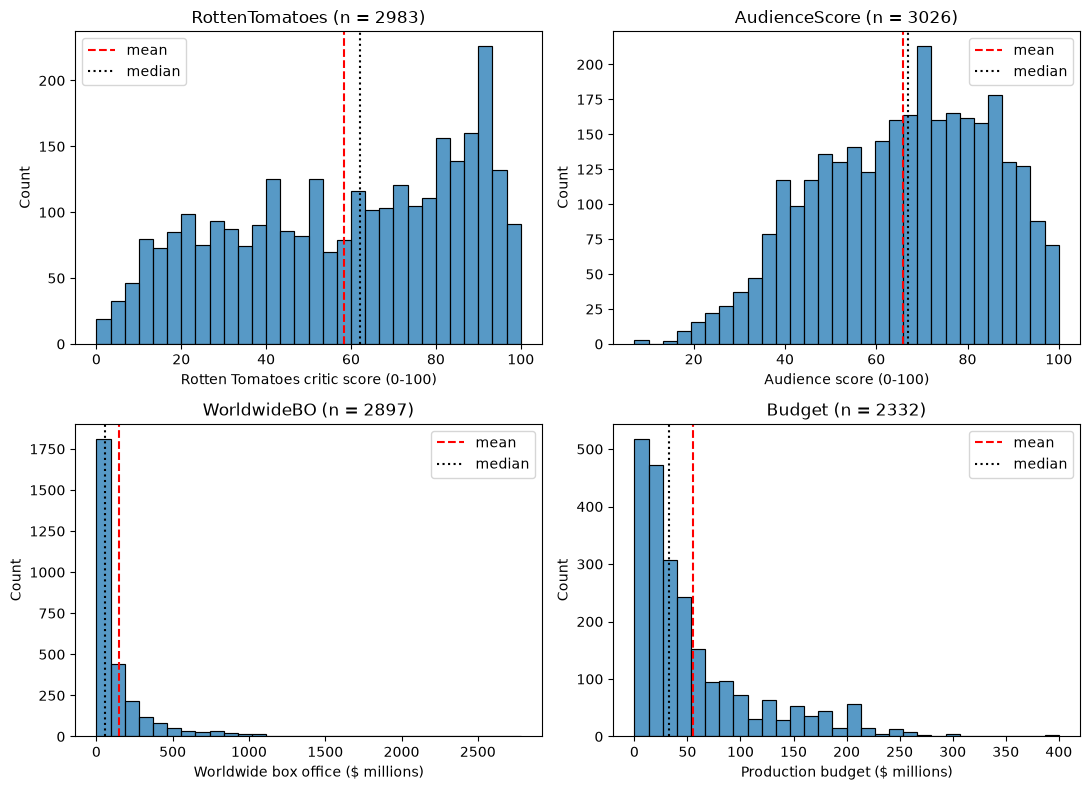

In [14]:
labels = {
    "RottenTomatoes": "Rotten Tomatoes critic score (0-100)",
    "AudienceScore": "Audience score (0-100)",
    "WorldwideBO": "Worldwide box office ($ millions)",
    "Budget": "Production budget ($ millions)",
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, cols):
    sns.histplot(movies[col].dropna(), bins=30, ax=ax)
    ax.axvline(movies[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(movies[col].median(), color="black", linestyle=":", label="median")
    ax.set_xlabel(labels[col])
    ax.set_title(f"{col} (n = {movies[col].notna().sum()})")
    ax.legend()
plt.tight_layout()
fig.savefig("histograms.png", dpi=200)
plt.show()

The two scores are spread across the whole 0-100 range (critic scores are more spread out, audience scores lean high). Worldwide box office and budget are both strongly right-skewed.

## Missing and impossible values

In [15]:
# Impossible values: scores outside 0-100, or box office / budget that are zero or negative
impossible = {
    "RottenTomatoes": ~movies["RottenTomatoes"].between(0, 100) & movies["RottenTomatoes"].notna(),
    "AudienceScore": ~movies["AudienceScore"].between(0, 100) & movies["AudienceScore"].notna(),
    "WorldwideBO": movies["WorldwideBO"] <= 0,
    "Budget": movies["Budget"] <= 0,
}
pd.DataFrame({
    "missing": movies[cols].isna().sum(),
    "impossible": pd.Series({c: m.sum() for c, m in impossible.items()}),
})

,missing,impossible
RottenTomatoes,126,0
AudienceScore,83,0
WorldwideBO,212,0
Budget,777,1


In [16]:
# Keep only movies that have every variable we need, with possible values
bad = pd.concat(impossible, axis=1).any(axis=1)
clean = movies[movies[cols].notna().all(axis=1) & ~bad].copy()
clean["Profit"] = clean["WorldwideBO"] / clean["Budget"]
print("Rows in original data:", len(movies))
print("Rows dropped:", len(movies) - len(clean))
print("Rows used in the analysis:", len(clean))

Rows in original data: 3109
Rows dropped: 796
Rows used in the analysis: 2313


All rows that were missing values were dropped as they need all 4 values for analysis.